# Notebook 3 de 3 — Unificación y dataset final

Reúne las imágenes de los notebooks 1 y 2 y aplica **el mismo paso final a todas**, sin importar su clase o tipo. Es la etapa que elimina las diferencias de formato que el modelo podría usar como atajo.

**Pasos**

1. Lee `manifest_reales.csv` (clase 0, auténticas) y `manifest_falsas.csv` (clase 1, manipuladas).
2. Verifica que todas las imágenes tengan el mismo tamaño (768×512).
3. Guarda **todas como JPEG** con el mismo procedimiento: calidad entre 75 y 95 asignada con un sorteo que **no depende de la clase**, mismo submuestreo de color y sin metadatos EXIF. Como hasta este paso todo estaba en PNG sin pérdida, esta compresión es la **única** y es igual para todas.
4. Compara la proporción de imágenes con **daño** en cada clase y ejecuta un **detector de atajos**: un modelo que intenta adivinar la clase usando solo datos del archivo (calidad JPEG, tamaño, peso). Si lo logra, existe un atajo que hay que corregir antes de entrenar.
5. Arma la carpeta final `03_dataset_final/` y la configuración de carpetas para la etapa de entrenamiento.

**Estructura generada**

```
03_dataset_final/
  autentica/   real_sano/   real_danado/
  manipulada/  inpaint_danio/   inpaint_control/   ia_danio/   ia_sano/
  manifest_final.csv
```

Cada tipo de imagen va en su propia carpeta, para poder medir el acierto del modelo **por tipo**.

## 1. Imports y configuración

In [1]:
import os, sys, zlib, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

In [2]:
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/deteccion-fraude-v2")
else:
    RAIZ = Path("./deteccion-fraude-v2")

MANIFEST_REALES = RAIZ / "01_reales" / "manifest_reales.csv"
MANIFEST_FALSAS = RAIZ / "02_falsas" / "manifest_falsas.csv"
FINAL           = RAIZ / "03_dataset_final"
MANIFEST_FINAL  = FINAL / "manifest_final.csv"

CANVAS_W, CANVAS_H = 768, 512
CALIDAD_MIN, CALIDAD_MAX = 75, 95        # rango de calidad JPEG, IGUAL para todas las clases
SUBMUESTREO = 2                          # 4:2:0 para todas
SEMILLA = 42
BALANCEAR_DANIO = False                  # True: iguala el % de daño entre clases descartando imágenes (ver sección 3)

CLASE_DE_TIPO = {"real_sano": 0, "real_danado": 0,
                 "inpaint_danio": 1, "inpaint_control": 1, "ia_danio": 1, "ia_sano": 1}
NOMBRE_CLASE = {0: "autentica", 1: "manipulada"}

Mounted at /content/drive


## 2. Unión de las tablas

Cada imagen queda con su clase (0/1), su tipo, si tiene daño (1/0) y su `base_id`: el identificador de la foto real de la que proviene. Las ediciones comparten el `base_id` de su original.

In [3]:
reales = pd.read_csv(MANIFEST_REALES)
falsas = pd.read_csv(MANIFEST_FALSAS)

df_r = pd.DataFrame({
    "origen": [str(RAIZ / "01_reales" / "base" / f"{i}.png") for i in reales["id"]],
    "nombre": reales["id"],
    "tipo": np.where(reales["tipo"] == "sano", "real_sano", "real_danado"),
    "danio": (reales["tipo"] == "danado").astype(int),
    "base_id": reales["id"],
})
df_f = pd.DataFrame({
    "origen": [str(RAIZ / a) for a in falsas["archivo"]],
    "nombre": [Path(a).stem for a in falsas["archivo"]],
    "tipo": falsas["tipo"],
    "danio": falsas["danio"].astype(int),
    "base_id": falsas["base_id"],
})
df = pd.concat([df_r, df_f], ignore_index=True)
df["clase"] = df["tipo"].map(CLASE_DE_TIPO)

faltan = [o for o in df["origen"] if not Path(o).exists()]
if faltan:
    raise FileNotFoundError(f"Faltan {len(faltan)} archivos, por ejemplo: {faltan[:3]}")

print("Imágenes por tipo:")
print(df.groupby(["clase", "tipo"]).size().to_string())

Imágenes por tipo:
clase  tipo           
0      real_danado        4
       real_sano          7
1      ia_danio           2
       ia_sano            2
       inpaint_control    4
       inpaint_danio      4


## 3. Proporción de daño por clase

Si en la clase manipulada casi todas las imágenes tuvieran daño y en la auténtica casi ninguna, el modelo podría asociar el golpe con la manipulación. Por eso se compara el porcentaje de imágenes con daño en cada clase: lo esperable es que sean parecidos.

In [4]:
pct = df.groupby("clase")["danio"].mean() * 100
print("Porcentaje de imágenes CON daño en cada clase:")
for c, v in pct.items():
    print(f"  clase {c} ({NOMBRE_CLASE[c]}): {v:.0f} %")

if len(pct) == 2 and abs(pct[0] - pct[1]) > 15:
    print("\nATENCIÓN: el daño está desparejo entre clases (diferencia mayor a 15 puntos): el modelo puede usarlo de pista.")
    print("Alternativas para corregirlo:")
    print("  1) Sumar fotos reales CON daño a la clase auténtica (notebook 1: consultas de 'danado' o fotos propias).")
    print("  2) BALANCEAR_DANIO = True: se descartan al azar imágenes manipuladas con daño hasta igualar.")
else:
    print("\nEl porcentaje de daño no separa las clases de forma evidente.")

Porcentaje de imágenes CON daño en cada clase:
  clase 0 (autentica): 36 %
  clase 1 (manipulada): 50 %

El porcentaje de daño no separa las clases de forma evidente.


In [5]:
if BALANCEAR_DANIO:
    objetivo = pct[0] / 100
    c1 = df[df["clase"] == 1]
    n_sin = int((c1["danio"] == 0).sum())
    n_con_objetivo = int(round(objetivo * n_sin / (1 - objetivo))) if objetivo < 1 else 0
    con = c1[c1["danio"] == 1]
    if len(con) > n_con_objetivo:
        # se descartan primero las 100 % IA con daño y después las ediciones con daño (al azar)
        orden = pd.concat([con[con["tipo"] == "ia_danio"].sample(frac=1, random_state=SEMILLA),
                           con[con["tipo"] == "inpaint_danio"].sample(frac=1, random_state=SEMILLA)])
        quitar = orden.head(len(con) - n_con_objetivo).index
        print(f"Balanceo: se descartan {len(quitar)} imágenes manipuladas con daño.")
        df = df.drop(index=quitar).reset_index(drop=True)
    print("Nuevo % con daño por clase:", (df.groupby("clase")["danio"].mean() * 100).round(0).to_dict())
else:
    print("BALANCEAR_DANIO = False: no se descarta nada.")

BALANCEAR_DANIO = False: no se descarta nada.


## 4. Compresión JPEG idéntica para todas

La **calidad** de cada imagen se calcula a partir de un número derivado de su nombre. Es determinista (cada ejecución produce el mismo resultado), cae en el mismo rango para todas y es independiente de la clase. Todas se guardan sin EXIF.

In [6]:
def calidad_para(nombre):
    return CALIDAD_MIN + zlib.crc32(nombre.encode()) % (CALIDAD_MAX - CALIDAD_MIN + 1)

import shutil
for c in NOMBRE_CLASE.values():                 # se borra solo lo generado por una ejecución anterior de este notebook
    if (FINAL / c).exists():
        shutil.rmtree(FINAL / c)
        print(f"Se regeneró la carpeta {c}/ (había una corrida anterior)")

filas = []
t0 = time.time()
for _, f in df.iterrows():
    carpeta = FINAL / NOMBRE_CLASE[f["clase"]] / f["tipo"]
    carpeta.mkdir(parents=True, exist_ok=True)
    destino = carpeta / f"{f['nombre']}.jpg"
    img = Image.open(f["origen"]).convert("RGB")
    if img.size != (CANVAS_W, CANVAS_H):
        raise ValueError(f"{f['origen']} tiene tamaño {img.size}, se esperaba {(CANVAS_W, CANVAS_H)}. "
                         "Revisá los notebooks 1 y 2 (deben usar el mismo CANVAS).")
    q = calidad_para(f["nombre"])
    img.save(destino, "JPEG", quality=q, subsampling=SUBMUESTREO, optimize=False)
    filas.append({**f.to_dict(), "archivo": str(destino.relative_to(FINAL)), "calidad_jpeg": q,
                  "kb": os.path.getsize(destino) / 1024})
df_final = pd.DataFrame(filas)
df_final.drop(columns=["origen"]).to_csv(MANIFEST_FINAL, index=False)
print(f"{len(df_final)} imágenes guardadas en {FINAL} ({time.time() - t0:.0f}s)")

23 imágenes guardadas en /content/drive/MyDrive/deteccion-fraude-v2/03_dataset_final (9s)


## 5. Detector de atajos

Se evalúa si es posible **adivinar la clase sin mirar la imagen**, solo con datos del archivo. Se usa una regresión logística con validación cruzada agrupada por foto base (`StratifiedGroupKFold`), para que una foto y sus ediciones no queden repartidas entre entrenamiento y validación. El resultado es un **AUC**: 0,5 indica que la clase no se puede adivinar y 1,0 que se adivina siempre.

- **Metadatos de codificación** (calidad JPEG medida en el archivo, ancho y alto): el AUC esperado es cercano a **0,5**. Lo que importa es **la distancia a 0,5**: un valor bastante mayor (por ejemplo 0,75) o bastante menor (por ejemplo 0,25) indica que la clase se puede adivinar con el archivo; en el segundo caso, "al revés". Se avisa si se aleja más de 0,10.
- **Peso del archivo en KB:** el resultado es **informativo**. Las imágenes más lisas pesan menos, así que es normal que haya algo de señal (las imágenes de IA pueden ser más suaves). Un AUC muy lejos de 0,5 (más de 0,85 o menos de 0,15) indicaría que el peso por sí solo casi separa las clases.

Con pocas imágenes (por ejemplo, el piloto de 23) el AUC es muy inestable: el aviso es confiable recién con cientos de imágenes.

In [7]:
def calidad_medida(ruta):
    with Image.open(ruta) as im:
        q0 = np.asarray(im.quantization[0], dtype=float)
    return float(q0.mean())                    # tabla de cuantización: menor = más calidad

df_final["q_medida"] = [calidad_medida(FINAL / a) for a in df_final["archivo"]]
df_final["ancho"] = CANVAS_W
df_final["alto"] = CANVAS_H

def auc_atajo(columnas):
    X = df_final[columnas].values.astype(float)
    y = df_final["clase"].values
    grupos = df_final["base_id"].values
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    prob = cross_val_predict(modelo, X, y, cv=cv, groups=grupos, method="predict_proba")[:, 1]
    return roc_auc_score(y, prob)

auc_meta = auc_atajo(["q_medida", "ancho", "alto"])
auc_peso = auc_atajo(["kb"])
print(f"AUC adivinando con metadatos de codificación: {auc_meta:.2f}   (esperado: cerca de 0.50)")
print(f"AUC adivinando solo con el peso del archivo:  {auc_peso:.2f}   (informativo)")
# un AUC lejos de 0,5 hacia cualquier lado es un atajo (por debajo de 0,5 la clase se adivina "al revés")
if abs(auc_meta - 0.5) > 0.10:
    print("\nATENCIÓN: los metadatos de codificación separan las clases (ver paso 4).")
if abs(auc_peso - 0.5) > 0.35:
    print("ATENCIÓN: el peso del archivo casi separa las clases; puede ser un atajo fácil para el modelo.")
if len(df_final) < 100:
    print(f"(Con {len(df_final)} imágenes el AUC es poco estable: tomarlo como orientativo.)")

resumen = (df_final.groupby(["clase", "tipo"])
             .agg(n=("kb", "count"), peso_kb_mediano=("kb", "median"), calidad_jpeg_mediana=("calidad_jpeg", "median"))
             .round(1))
resumen

AUC adivinando con metadatos de codificación: 0.20   (esperado: cerca de 0.50)
AUC adivinando solo con el peso del archivo:  0.43   (informativo)


n  peso_kb_mediano  calidad_jpeg_mediana
clase tipo                                                     
0     real_danado      4            108.6                  85.5
      real_sano        7            116.1                  86.0
1     ia_danio         2             61.4                  75.5
      ia_sano          2             99.7                  89.5
      inpaint_control  4            115.6                  90.0
      inpaint_danio    4             88.5                  80.0

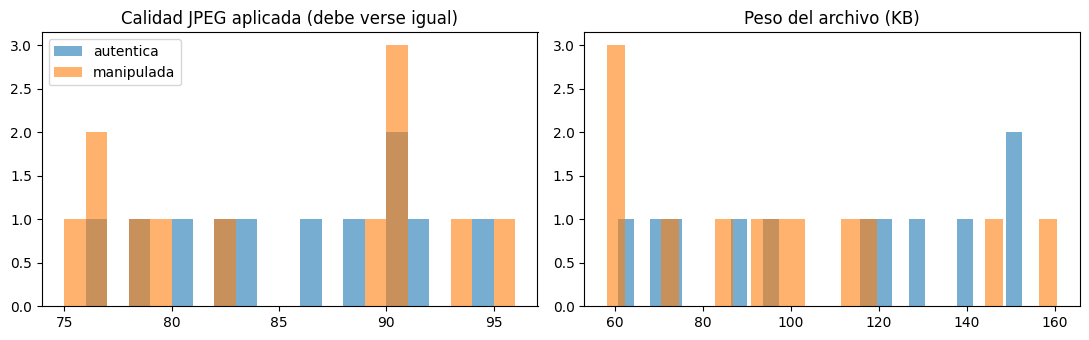

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for c in [0, 1]:
    s = df_final[df_final["clase"] == c]
    ax[0].hist(s["calidad_jpeg"], bins=range(CALIDAD_MIN, CALIDAD_MAX + 2), alpha=0.6, label=NOMBRE_CLASE[c])
    ax[1].hist(s["kb"], bins=25, alpha=0.6, label=NOMBRE_CLASE[c])
ax[0].set_title("Calidad JPEG aplicada (debe verse igual)"); ax[1].set_title("Peso del archivo (KB)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 6. Configuración de carpetas para el entrenamiento

El notebook 4 (`04_entrenamiento_convnext.ipynb`) lee directamente `manifest_final.csv`; la celda siguiente muestra un resumen de las carpetas por clase. Al mantener una carpeta por tipo de imagen, la evaluación puede informar el acierto **por tipo** (por ejemplo, si al modelo le cuesta más `inpaint_control` que `ia_sano`).

In [9]:
carpetas_por_clase = {c: sorted(f"{NOMBRE_CLASE[c]}/{t}" for t in df_final[df_final["clase"] == c]["tipo"].unique())
                      for c in [0, 1]}
print("# --- Configuración de carpetas para el entrenamiento ---")
print('RAIZ = Path("/content/drive/MyDrive/deteccion-fraude-v2/03_dataset_final")')
print("CARPETAS_POR_CLASE = {")
for c, lista in carpetas_por_clase.items():
    print(f"    {c}: {lista},")
print("}")
print()
print(f"Total: {len(df_final)} imágenes | clase 0: {(df_final['clase'] == 0).sum()} | clase 1: {(df_final['clase'] == 1).sum()}")

# --- Configuración de carpetas para el entrenamiento ---
RAIZ = Path("/content/drive/MyDrive/deteccion-fraude-v2/03_dataset_final")
CARPETAS_POR_CLASE = {
    0: ['autentica/real_danado', 'autentica/real_sano'],
    1: ['manipulada/ia_danio', 'manipulada/ia_sano', 'manipulada/inpaint_control', 'manipulada/inpaint_danio'],
}

Total: 23 imágenes | clase 0: 11 | clase 1: 12


## 7. Sesgos que permanecen

El diseño elimina los atajos más importantes, pero no todos:

- **Las imágenes 100 % IA no tienen una foto real de origen.** Cambian el contenido y el estilo de la escena. Las ediciones (`inpaint_danio`, `inpaint_control`) son la prueba más exigente: misma foto, con un cambio solo en la zona editada. Si el modelo acierta mucho en las imágenes 100 % IA y poco en las ediciones, aprendió la diferencia más fácil.
- **Las fotos reales de Commons** provienen de cámaras y celulares distintos, cada uno con su propio procesamiento. Las fotos tomadas con celular se acercan más a las de un siniestro real.
- **Es un dataset de estudio** y de volumen chico. Los resultados sirven para comparar variantes del modelo, no para asegurar su desempeño en producción.